# Module 15 — Generalisation and Statistical Learning Theory

This notebook turns the ideas of the module into experiments you can edit and re-run: a
memorising learner whose training error lies, the Hoeffding bound against the real tail of a
test accuracy, the optimism of picking the best of many models, shattering pictures and the
VC bound, the $1/n$ learning curve PAC theory predicts, margins and early stopping as capacity
control, double descent with random features, gradient descent finding the minimum-norm
interpolator, learning curves with a fitted power law, covariate shift, and a leakage trap.

Read the [concept guide](README.md) first, or keep it open alongside — every section here
mirrors a numbered section there. Everything is built **from scratch in NumPy**; scikit-learn
appears only in the last section, to show the leakage-proof `Pipeline`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (7, 4)
np.set_printoptions(precision=4, suppress=True)

## 1. The generalisation question — a report card the model wrote itself

True risk $R(h) = \mathbb{E}[\ell(h(x), y)]$ is what you care about; the training error
$\hat R_S(h)$ is what you can see. For a hypothesis chosen *using* the sample the two can be
arbitrarily far apart. The extreme case is a **memoriser**: it stores every training point and
predicts the majority class elsewhere, so its training error is zero whatever the labels.

Data: $x \sim \text{Uniform}[0, 6]$, label $y = \mathbf{1}[x \ge 2.5]$ with 10 % of labels
flipped, so the Bayes risk is $0.1$. We compare the memoriser with an honest **threshold
learner** (ERM over all cut points) and estimate each one's *true* risk on a fresh sample of
200,000 points — something you can do with synthetic data and never with real data.

In [2]:
def make_data(n, g, flip=0.10):
    x = g.uniform(0, 6, n)
    y = (x >= 2.5).astype(int)
    flipped = g.random(n) < flip
    y[flipped] = 1 - y[flipped]
    return x, y

class Memoriser:
    def fit(self, x, y):
        self.table = dict(zip(x.tolist(), y.tolist()))
        self.majority = int(np.round(y.mean()))
        return self
    def predict(self, x):
        return np.array([self.table.get(v, self.majority) for v in x.tolist()])

class ThresholdLearner:                    # ERM over h_a(x) = 1[x >= a]
    def fit(self, x, y):
        xs = np.sort(x)
        cands = np.concatenate([[xs[0] - 1], (xs[:-1] + xs[1:]) / 2, [xs[-1] + 1]])
        errs = [np.mean((x >= a).astype(int) != y) for a in cands]
        self.a = cands[int(np.argmin(errs))]
        return self
    def predict(self, x):
        return (x >= self.a).astype(int)

x_tr, y_tr = make_data(50, rng)
x_fresh, y_fresh = make_data(200_000, rng)          # stands in for the population
print(f"{'learner':18s} {'training error':>15s} {'true risk (fresh)':>18s}")
for model in (Memoriser(), ThresholdLearner()):
    model.fit(x_tr, y_tr)
    tr = np.mean(model.predict(x_tr) != y_tr)
    te = np.mean(model.predict(x_fresh) != y_fresh)
    print(f"{type(model).__name__:18s} {tr:15.3f} {te:18.3f}")
print(f"\nthreshold found: a = {model.a:.3f}  (truth 2.5);  Bayes risk = 0.100")

learner             training error  true risk (fresh)
Memoriser                    0.000              0.432
ThresholdLearner             0.120              0.103

threshold found: a = 2.474  (truth 2.5);  Bayes risk = 0.100


The memoriser reports a perfect training score and has a true risk of about $0.43$ — the error
of always predicting the majority class ($P(y = 1) = 0.567$ here), which is what it does on every
point it has not seen. It has learned nothing. The threshold learner's training error (0.12) is close to its true risk (0.10)
because the class it searches is tiny: there is little room to fit the sample's accidents.
The rest of the module quantifies "little room".

**Try it yourself:** set `flip=0.3` in both `make_data` calls. The memoriser still scores
zero on training; what happens to the threshold learner's gap?

## 2. Approximation error versus estimation error

Excess risk $= [R(h^*_{\mathcal H}) - R^*] + [R(\hat h_S) - R(h^*_{\mathcal H})]$: what the
best member of the class misses (approximation) plus what the finite sample costs (estimation).
We regress $y = \sin(2\pi x) + \varepsilon$, $\sigma = 0.3$, with polynomial classes of
increasing degree and $n = 20$ points, measuring each term directly:

* approximation error = population MSE of the best polynomial (fitted on a dense noiseless grid);
* estimation error = average excess risk of the least-squares fit over 200 training sets, minus the approximation error.

degree  approximation  estimation  excess risk
     0         0.4998      0.0322       0.5319
     1         0.1964      0.0345       0.2309
     2         0.1964      0.0941       0.2905
     3         0.0044      0.0336       0.0380
     4         0.0044      0.0827       0.0871
     5         0.0000      0.2600       0.2600
     7         0.0000     56.3281      56.3281
     9         0.0000  16971.2841   16971.2841


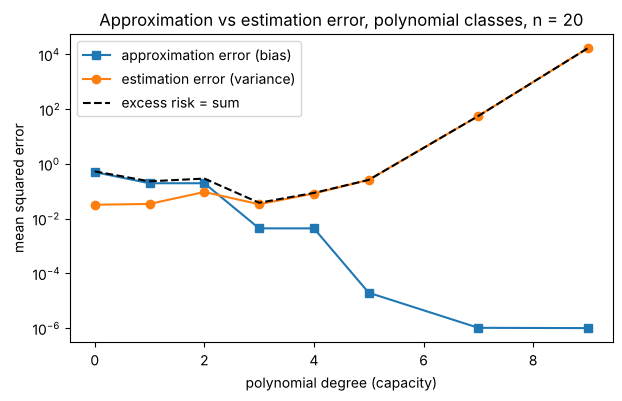

In [3]:
f_true = lambda x: np.sin(2 * np.pi * x)
grid = np.linspace(0, 1, 2001)
n_train, sigma, n_sets = 20, 0.3, 200

degrees = [0, 1, 2, 3, 4, 5, 7, 9]
approx, estim = [], []
for deg in degrees:
    best_c = np.polyfit(grid, f_true(grid), deg)                  # best in class (population)
    approx.append(np.mean((np.polyval(best_c, grid) - f_true(grid)) ** 2))
    risks = []
    for _ in range(n_sets):
        x = rng.uniform(0, 1, n_train)
        y = f_true(x) + sigma * rng.normal(size=n_train)
        c = np.polyfit(x, y, deg)
        risks.append(np.mean((np.polyval(c, grid) - f_true(grid)) ** 2))   # excess risk (noise excluded)
    estim.append(np.mean(risks) - approx[-1])
approx, estim = np.array(approx), np.array(estim)

print(f"{'degree':>6s} {'approximation':>14s} {'estimation':>11s} {'excess risk':>12s}")
for d, a, e in zip(degrees, approx, estim):
    print(f"{d:6d} {a:14.4f} {e:11.4f} {a + e:12.4f}")

plt.semilogy(degrees, approx + 1e-6, "s-", label="approximation error (bias)")
plt.semilogy(degrees, estim, "o-", label="estimation error (variance)")
plt.semilogy(degrees, approx + estim, "k--", label="excess risk = sum")
plt.title(f"Approximation vs estimation error, polynomial classes, n = {n_train}")
plt.xlabel("polynomial degree (capacity)"); plt.ylabel("mean squared error"); plt.legend(); plt.show()

Approximation error collapses once the class contains a good approximation of the sine (degree
3 and above); estimation error grows with degree and explodes past degree 5 on 20 points. Their
sum is the classical U-curve — the bias–variance trade-off of Module 13 in the language of
learning theory. Notice that the estimation error of degree 0 and 1 is not zero: even a class
that is far too small pays a sample-size price.

## 3. Concentration: Hoeffding versus the real tail of a test accuracy

For a *fixed* classifier with true accuracy $p$, each test example is a Bernoulli$(p)$ trial,
and the measured accuracy $\hat p$ is a mean of $n$ variables in $[0, 1]$. Hoeffding:

$$P(|\hat p - p| \ge t) \le 2e^{-2nt^2}, \qquad \text{Chebyshev: } P(|\hat p - p| \ge t) \le \frac{p(1-p)}{nt^2}.$$

We simulate 20,000 test sets of size $n = 200$ for a model with $p = 0.7$ and compare the
empirical tail with both bounds.

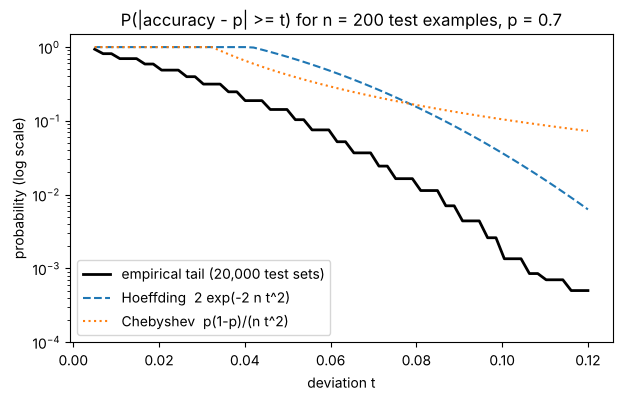

t = 0.05: empirical 0.1426   Hoeffding 0.7408   Chebyshev 0.4229
t = 0.08: empirical 0.0164   Hoeffding 0.1641   Chebyshev 0.1680
t = 0.10: empirical 0.0014   Hoeffding 0.0352   Chebyshev 0.1039

sample size for +-0.02 at 95%:  Hoeffding n >= 4,612   Chebyshev n >= 12,500   normal approx n ~ 2,401


In [4]:
n, p_true, n_rep = 200, 0.7, 20_000
acc = rng.binomial(n, p_true, size=n_rep) / n
ts = np.linspace(0.005, 0.12, 60)
empirical = np.array([np.mean(np.abs(acc - p_true) >= t) for t in ts])
hoeffding = np.minimum(1, 2 * np.exp(-2 * n * ts ** 2))
chebyshev = np.minimum(1, p_true * (1 - p_true) / (n * ts ** 2))

plt.semilogy(ts, empirical, "k-", lw=2, label="empirical tail (20,000 test sets)")
plt.semilogy(ts, hoeffding, "--", label="Hoeffding  2 exp(-2 n t^2)")
plt.semilogy(ts, chebyshev, ":", label="Chebyshev  p(1-p)/(n t^2)")
plt.ylim(1e-4, 1.5)
plt.title(f"P(|accuracy - p| >= t) for n = {n} test examples, p = {p_true}")
plt.xlabel("deviation t"); plt.ylabel("probability (log scale)"); plt.legend(); plt.show()

for t in (0.05, 0.08, 0.10):
    i = np.argmin(np.abs(ts - t))
    print(f"t = {t:.2f}: empirical {empirical[i]:.4f}   Hoeffding {hoeffding[i]:.4f}   Chebyshev {chebyshev[i]:.4f}")

eps, delta = 0.02, 0.05
print(f"\nsample size for +-{eps} at {1-delta:.0%}:  Hoeffding n >= {int(np.ceil(np.log(2/delta)/(2*eps**2))):,}"
      f"   Chebyshev n >= {int(np.ceil(1/(4*delta*eps**2) - 1e-9)):,}   normal approx n ~ {int(np.ceil(1.96**2*0.25/eps**2 - 1e-9)):,}")

Both bounds are valid (they sit above the black curve everywhere) and both are loose. For small
$t$ Chebyshev is actually tighter; once $nt^2$ exceeds about one, Hoeffding's exponential
decay takes over and leaves Chebyshev's $1/t^2$ far behind. That exponential tail is what makes
the union bound affordable in the next section: multiplying an exponentially small probability
by a large number of hypotheses costs only a logarithm.

**Try it yourself:** change `p_true` to `0.95`. The empirical tail tightens a lot (the
variance $p(1-p)$ shrinks), Chebyshev follows it, Hoeffding does not — it only knows the range.

## 4. The union bound and the optimism of the best of $m$ models

Evaluate $m$ models on a validation set of $n$ examples and keep the best score. Even if all
$m$ have the *same* true accuracy $a$, the maximum of $m$ noisy scores sits above $a$. Two
predictions:

* **expected optimism** $\approx \mathbb{E}[\max \text{ of } m \text{ standard normals}] \cdot \sqrt{a(1-a)/n}$
  (the normal approximation, with $0.56, 1.16, 1.54, 2.25, 2.51$ for $m = 2, 5, 10, 50, 100$);
* **union-bound envelope**: $P(\max_j \hat a_j - a \ge t) \le m\,e^{-2nt^2}$, so with probability
  $\ge 0.95$ the optimism is below $\sqrt{\ln(m/0.05)/(2n)}$.

true accuracy of every model: 0.8, validation size 1000, SE of one score 0.0126

   m  mean optimism  E[max] theory  95% quantile  union bound
   1        -0.0001         0.0000        0.0210       0.0387
   2         0.0070         0.0071        0.0240       0.0429
   3         0.0108         0.0107        0.0270       0.0452
   5         0.0144         0.0147        0.0290       0.0480
  10         0.0193         0.0195        0.0320       0.0515
  20         0.0233         0.0236        0.0340       0.0547
  50         0.0281         0.0284        0.0380       0.0588
 100         0.0309         0.0317        0.0400       0.0616
 200         0.0341         0.0347        0.0430       0.0644


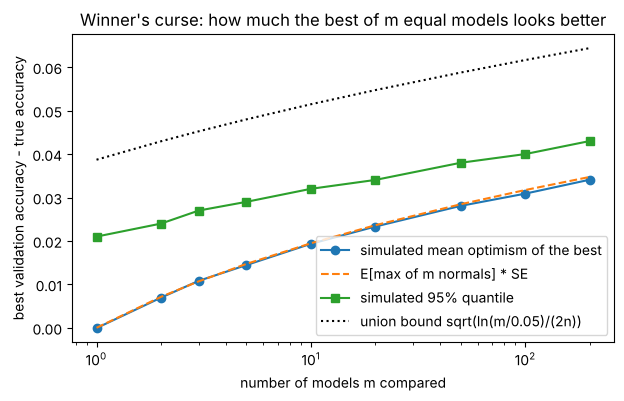

In [5]:
from scipy import stats, integrate

def expected_max_normal(m):
    f = lambda z: z * m * stats.norm.pdf(z) * stats.norm.cdf(z) ** (m - 1)
    return integrate.quad(f, -10, 10)[0]

a_true, n_val, n_rep = 0.8, 1000, 2000
ms = np.array([1, 2, 3, 5, 10, 20, 50, 100, 200])
se = np.sqrt(a_true * (1 - a_true) / n_val)
optimism = np.zeros(len(ms)); q95 = np.zeros(len(ms))
for j, m in enumerate(ms):
    best = rng.binomial(n_val, a_true, size=(n_rep, m)).max(axis=1) / n_val
    optimism[j] = np.mean(best) - a_true
    q95[j] = np.quantile(best, 0.95) - a_true
theory = np.array([expected_max_normal(m) for m in ms]) * se
envelope = np.sqrt(np.log(ms / 0.05) / (2 * n_val))

print(f"true accuracy of every model: {a_true}, validation size {n_val}, SE of one score {se:.4f}\n")
print(f"{'m':>4s} {'mean optimism':>14s} {'E[max] theory':>14s} {'95% quantile':>13s} {'union bound':>12s}")
for m, o, t, q, e in zip(ms, optimism, theory, q95, envelope):
    print(f"{m:4d} {o:14.4f} {t:14.4f} {q:13.4f} {e:12.4f}")

plt.semilogx(ms, optimism, "o-", label="simulated mean optimism of the best")
plt.semilogx(ms, theory, "--", label="E[max of m normals] * SE")
plt.semilogx(ms, q95, "s-", label="simulated 95% quantile")
plt.semilogx(ms, envelope, "k:", label="union bound sqrt(ln(m/0.05)/(2n))")
plt.title("Winner's curse: how much the best of m equal models looks better")
plt.xlabel("number of models m compared"); plt.ylabel("best validation accuracy - true accuracy"); plt.legend(); plt.show()

Picking the best of ten identical models buys about two points of phantom accuracy on a
1,000-example validation set; the best of a hundred, over three. The normal-approximation line
tracks the simulation closely, and the union-bound envelope — distribution-free, worst-case —
sits above the simulated 95 % quantile everywhere while growing with the same
$\sqrt{\ln m}$ shape. This is `GridSearchCV.best_score_` being optimistic, and the reason the
final model gets a fresh test set (Section 10).

**Try it yourself:** set `n_val = 10_000`. The optimism shrinks by $\sqrt{10} \approx 3.2$ —
the only cure for the winner's curse, besides looking less often, is a bigger validation set.

## 5. Shattering, the growth function and the VC bound

A class **shatters** $n$ points if it realises all $2^n$ labellings of them; the VC dimension
is the largest such $n$. For lines in the plane, three points in general position are shattered
(all 8 patterns) and four are not: the XOR labelling of four points in convex position cannot be
cut by any line. So $d_{\mathrm{VC}} = 3 = d + 1$.

Below we check every labelling by brute force: for each pattern we ask whether a linear
classifier $\operatorname{sign}(w^\top x + b)$ separates it, by solving a small linear feasibility
problem (does some $(w, b)$ satisfy $y_i(w^\top x_i + b) \ge 1$ for all $i$?).

3 points: 8 of 8 labellings realised by lines -> shattered: True
4 points (square): 14 of 16 realised -> shattered: False
labellings no line can realise on the square: [(-1, 1, -1, 1), (1, -1, 1, -1)]


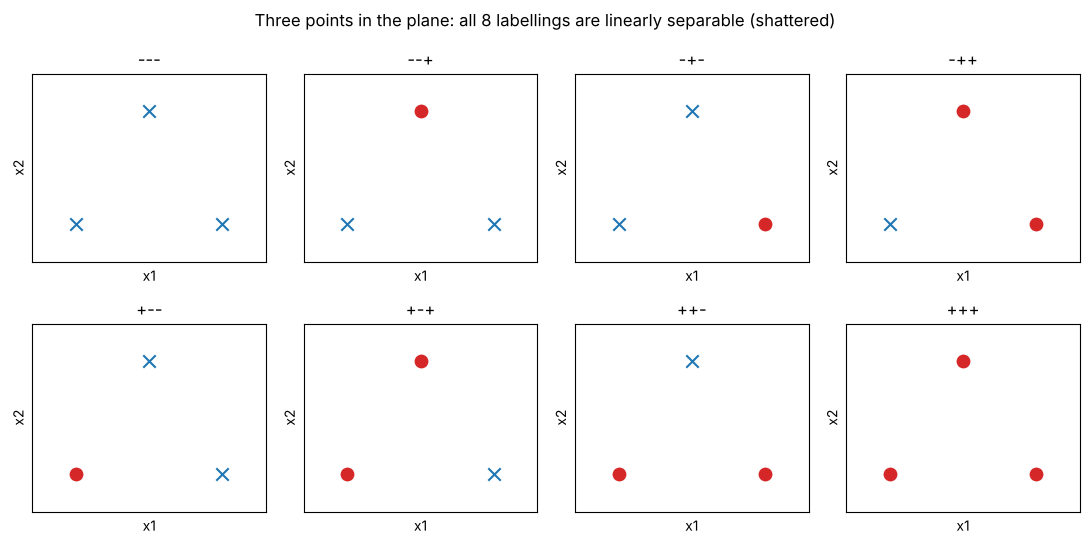

In [6]:
from itertools import product
from scipy.optimize import linprog

def linearly_separable(X, y):
    # feasibility of  y_i (w.x_i + b) >= 1  <=>  -y_i (w.x_i + b) <= -1 ; variables (w1, w2, b)
    A = -(y[:, None] * np.column_stack([X, np.ones(len(X))]))
    res = linprog(c=np.zeros(3), A_ub=A, b_ub=-np.ones(len(X)), bounds=[(None, None)] * 3, method="highs")
    return res.status == 0

def realised_dichotomies(X):
    return [np.array(lab) for lab in product([-1, 1], repeat=len(X)) if linearly_separable(X, np.array(lab))]

P3 = np.array([[0., 0.], [1., 0.], [0.5, 0.9]])
P4 = np.array([[0., 0.], [1., 0.], [1., 1.], [0., 1.]])
dich3, dich4 = realised_dichotomies(P3), realised_dichotomies(P4)
print(f"3 points: {len(dich3)} of {2**3} labellings realised by lines -> shattered: {len(dich3) == 8}")
print(f"4 points (square): {len(dich4)} of {2**4} realised -> shattered: {len(dich4) == 16}")
missing = [lab for lab in product([-1, 1], repeat=4) if not linearly_separable(P4, np.array(lab))]
print("labellings no line can realise on the square:", missing)

fig, axes = plt.subplots(2, 4, figsize=(11, 5.5))
for ax, lab in zip(axes.ravel(), dich3):
    ax.scatter(P3[lab == 1, 0], P3[lab == 1, 1], c="tab:red", s=80, marker="o", label="+1")
    ax.scatter(P3[lab == -1, 0], P3[lab == -1, 1], c="tab:blue", s=80, marker="x", label="-1")
    ax.set_xlim(-0.3, 1.3); ax.set_ylim(-0.3, 1.2); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title("".join("+" if l == 1 else "-" for l in lab)); ax.set_xlabel("x1"); ax.set_ylabel("x2")
fig.suptitle("Three points in the plane: all 8 labellings are linearly separable (shattered)")
plt.tight_layout(); plt.show()

Every one of the eight patterns on three points is separable; on the four corners of a square
exactly the two XOR patterns ($+,-,+,-$ and $-,+,-,+$) are not. Fourteen of sixteen is also
what the general-position formula $\Pi(n) = n^2 - n + 2$ predicts for lines on $n = 4$ points.

### Growth function versus $2^n$, Sauer's lemma, and the bounds as curves in $n$

Sauer's lemma: if $d_{\mathrm{VC}} = d$, then $\Pi(n) \le \sum_{i=0}^{d}\binom{n}{i} \le (en/d)^d$ — a
polynomial, not an exponential. We count the dichotomies lines realise on random point sets
directly (every realisable labelling of points in general position can be obtained from a line
through two of the points, perturbed) and compare. Then we draw the uniform-deviation bounds
themselves as functions of $n$: finite class $\sqrt{\ln(2|\mathcal H|/\delta)/(2n)}$, VC class
$\sqrt{2d\ln(en/d)/n} + \sqrt{\ln(1/\delta)/(2n)}$.

  n  lines realise  n^2-n+2  Sauer bound (d=3)    2^n
  2              4        4                  4      4
  3              8        8                  8      8
  4             14       14                 15     16
  5             22       22                 26     32
  6             32       32                 42     64
  7             44       44                 64    128
  8             58       58                 93    256
  9             74       74                130    512
 10             92       92                176   1024
 11            112      112                232   2048
 12            134      134                299   4096


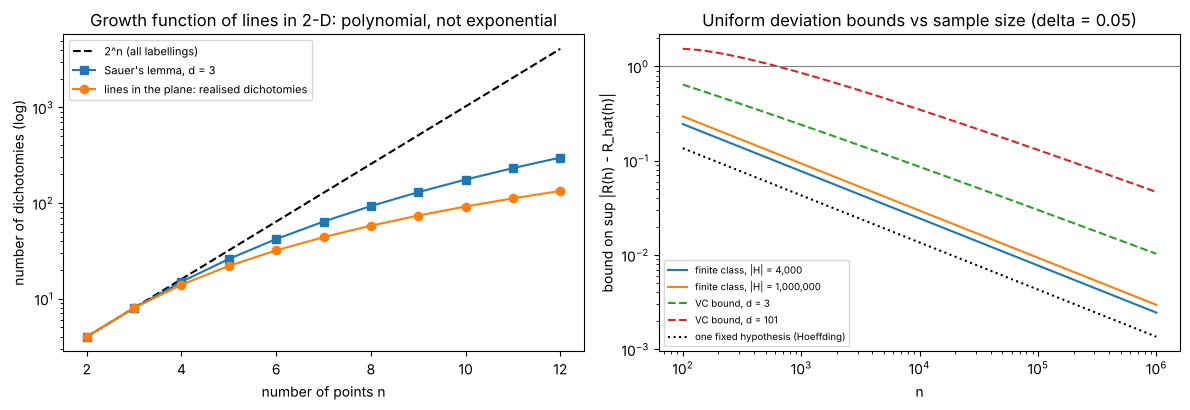

n =   1,000: Hoeffding 0.0429   |H| = 4,000: 0.0774   VC d=3: 0.2408
n =  10,000: Hoeffding 0.0136   |H| = 4,000: 0.0245   VC d=3: 0.0862
n = 100,000: Hoeffding 0.0043   |H| = 4,000: 0.0077   VC d=3: 0.0300


In [7]:
from math import comb

def count_line_dichotomies(P):
    # all labellings realisable by a line through points i, j (with i, j labelled either way), plus the two constant ones
    n = len(P); seen = {tuple([1] * n), tuple([0] * n)}
    for i in range(n):
        for j in range(i + 1, n):
            d = P[j] - P[i]; normal = np.array([-d[1], d[0]])
            side = ((P - P[i]) @ normal > 0).astype(int)
            for li in (0, 1):
                for lj in (0, 1):
                    lab = side.copy(); lab[i], lab[j] = li, lj
                    seen.add(tuple(lab)); seen.add(tuple(1 - lab))
    return len(seen)

ns_pts = np.arange(2, 13)
counted = np.array([count_line_dichotomies(rng.normal(size=(n, 2))) for n in ns_pts])
formula = ns_pts ** 2 - ns_pts + 2
sauer = np.array([sum(comb(int(n), i) for i in range(4)) for n in ns_pts])       # d = 3
print(f"{'n':>3s} {'lines realise':>14s} {'n^2-n+2':>8s} {'Sauer bound (d=3)':>18s} {'2^n':>6s}")
for n, c, f_, s_ in zip(ns_pts, counted, formula, sauer):
    print(f"{n:3d} {c:14d} {f_:8d} {s_:18d} {2**n:6d}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].semilogy(ns_pts, 2.0 ** ns_pts, "k--", label="2^n (all labellings)")
axes[0].semilogy(ns_pts, sauer, "s-", label="Sauer's lemma, d = 3")
axes[0].semilogy(ns_pts, counted, "o-", label="lines in the plane: realised dichotomies")
axes[0].set_title("Growth function of lines in 2-D: polynomial, not exponential")
axes[0].set_xlabel("number of points n"); axes[0].set_ylabel("number of dichotomies (log)"); axes[0].legend(fontsize=8)

ns = np.logspace(2, 6, 100); delta = 0.05
for H in (4_000, 1_000_000):
    axes[1].loglog(ns, np.sqrt(np.log(2 * H / delta) / (2 * ns)), label=f"finite class, |H| = {H:,}")
for d in (3, 101):
    vc = np.sqrt(2 * d * np.log(np.e * ns / d) / ns) + np.sqrt(np.log(1 / delta) / (2 * ns))
    axes[1].loglog(ns, vc, "--", label=f"VC bound, d = {d}")
axes[1].loglog(ns, np.sqrt(np.log(2 / delta) / (2 * ns)), "k:", label="one fixed hypothesis (Hoeffding)")
axes[1].axhline(1, color="gray", lw=0.8)
axes[1].set_title("Uniform deviation bounds vs sample size (delta = 0.05)")
axes[1].set_xlabel("n"); axes[1].set_ylabel("bound on sup |R(h) - R_hat(h)|"); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

for n in (1_000, 10_000, 100_000):
    vc3 = np.sqrt(2 * 3 * np.log(np.e * n / 3) / n) + np.sqrt(np.log(1 / delta) / (2 * n))
    print(f"n = {n:>7,d}: Hoeffding {np.sqrt(np.log(2/delta)/(2*n)):.4f}   |H| = 4,000: {np.sqrt(np.log(8000/delta)/(2*n)):.4f}   VC d=3: {vc3:.4f}")

Left: up to $n = 3$ the class realises everything; from $n = 4$ it falls further and further
below $2^n$, and Sauer's cubic bound holds with room to spare. Learning is possible because the
number of *behaviours* a class can show on a sample is tiny compared with the number of
labellings, so the union bound over behaviours (rather than hypotheses) is affordable.

Right: all bounds fall like $1/\sqrt{n}$ (slope $-1/2$ on the log–log plot); the price of a
class is a vertical offset — a factor, not a change of rate. A million hypotheses cost barely
twice the deviation of one. The VC bound for linear classifiers in 100 dimensions ($d = 101$)
is above 1, i.e. vacuous, until $n \approx 630$, and still $0.35$ at $n = 10{,}000$ — true to
its worst-case nature, and far more pessimistic than what you will see in Section 6.

## 6. PAC learning: the realisable rate is $1/n$

PAC theory says the sample complexity of a class with finite VC dimension scales like
$d/\varepsilon$ when some hypothesis is perfect (realisable), and like $d/\varepsilon^2$ otherwise.
Turned around: the error of ERM should fall like $1/n$ in the realisable case.

The class of intervals ($d_{\mathrm{VC}} = 2$) makes this exact. The ERM rule "tightest interval
around the positive examples" has true risk equal to the length of the two uncovered slivers,
which we can compute exactly instead of estimating.

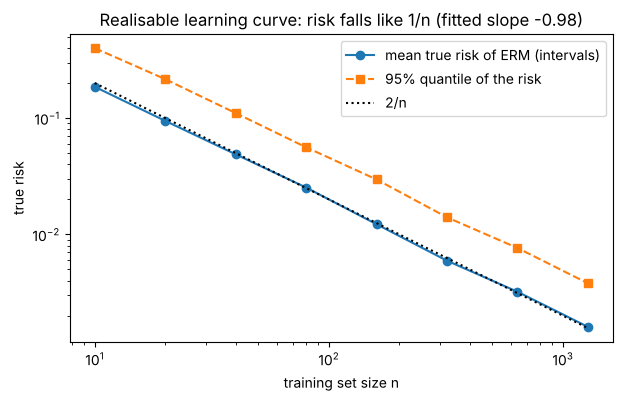

n       : [  10   20   40   80  160  320  640 1280]
risk    : [0.1857 0.0946 0.0488 0.0253 0.0122 0.0059 0.0032 0.0016]
risk * n: [1.86 1.89 1.95 2.02 1.95 1.9  2.05 2.05]   -> roughly constant, as 1/n predicts


In [8]:
a_true, b_true = 0.3, 0.7                         # target interval; x ~ Uniform[0, 1]

def erm_interval(x, y):
    pos = x[y == 1]
    return (pos.min(), pos.max()) if len(pos) else (0.0, 0.0)

ns = np.array([10, 20, 40, 80, 160, 320, 640, 1280])
risk = np.zeros(len(ns)); q95 = np.zeros(len(ns))
for i, n in enumerate(ns):
    r = []
    for _ in range(400):
        x = rng.uniform(0, 1, n); y = ((x >= a_true) & (x <= b_true)).astype(int)
        a, b = erm_interval(x, y)
        r.append((a - a_true) + (b_true - b))          # exact true risk of the learned interval
    risk[i], q95[i] = np.mean(r), np.quantile(r, 0.95)
slope = np.polyfit(np.log(ns), np.log(risk), 1)[0]

plt.loglog(ns, risk, "o-", label="mean true risk of ERM (intervals)")
plt.loglog(ns, q95, "s--", label="95% quantile of the risk")
plt.loglog(ns, 2 / ns, "k:", label="2/n")
plt.title(f"Realisable learning curve: risk falls like 1/n (fitted slope {slope:.2f})")
plt.xlabel("training set size n"); plt.ylabel("true risk"); plt.legend(); plt.show()
print("n       :", ns)
print("risk    :", np.round(risk, 4))
print("risk * n:", np.round(risk * ns, 2), "  -> roughly constant, as 1/n predicts")

The fitted slope is about $-1$: doubling the data halves the error, the realisable PAC rate.
With label noise the same experiment gives slope $-1/2$ (the agnostic rate), because the
learner must then *average out* noise rather than merely *locate* a boundary. Compare the
actual risk at $n = 1{,}000$ (about $0.002$) with the VC bound's $0.24$ from Section 5: the
bound's shape is right, its constant is a hundred times too pessimistic.

**Try it yourself:** flip 10 % of the labels inside the loop (`y[rng.random(n) < 0.1] ^= 1`)
and replace the exact risk by an estimate on fresh points. What slope do you get now?

## 7. Capacity control: margins and early stopping

### Margin, not dimension

For linear separators with $\|x\| \le r$ and normalised margin $\rho = \min_i y_i w^\top x_i / \|w\|$,
the margin bound says the capacity is $(r/\rho)^2$ — independent of the dimension. We generate
separable data in $\mathbb{R}^{10}$ with a true margin of $0.15$, collect several hundred
*different* separators that all classify the 30 training points perfectly, and plot each one's
test error against its margin. Then we run gradient descent on the logistic loss, whose direction
converges to the maximum-margin separator.

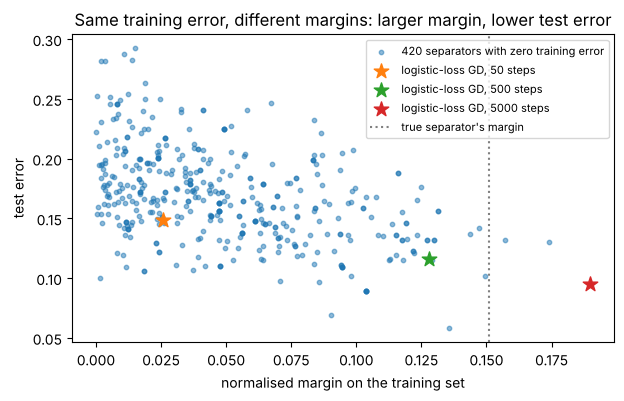

correlation(margin, test error) = -0.461
margin in [0.00, 0.02): 116 separators, mean test error 0.188
margin in [0.02, 0.05): 135 separators, mean test error 0.175
margin in [0.05, 0.20): 169 separators, mean test error 0.149


In [9]:
def separable_data(n, g, d=10, margin=0.15):
    w_star = g.normal(size=d); w_star /= np.linalg.norm(w_star)
    X = g.normal(size=(8 * n, d)); X /= np.linalg.norm(X, axis=1, keepdims=True)   # r = 1
    X = X[np.abs(X @ w_star) >= margin][:n]
    return X, np.sign(X @ w_star), w_star

def perceptron(X, y, order):
    w = np.zeros(X.shape[1])
    for _ in range(200):
        mistakes = 0
        for i in order:
            if y[i] * (X[i] @ w) <= 0:
                w += y[i] * X[i]; mistakes += 1
        if mistakes == 0:
            break
    return w

def margin_of(w, X, y):
    return np.min(y * (X @ w)) / np.linalg.norm(w)

X_tr, y_tr, w_star = separable_data(30, rng)
X_te = rng.normal(size=(5000, 10)); X_te /= np.linalg.norm(X_te, axis=1, keepdims=True)
y_te = np.sign(X_te @ w_star)

separators = [perceptron(X_tr, y_tr, rng.permutation(30)) for _ in range(300)]
for _ in range(3000):                                 # random consistent separators in dual form
    alpha = rng.exponential(size=30) * (rng.random(30) < 0.3)
    w = (alpha * y_tr) @ X_tr
    if np.linalg.norm(w) > 0 and np.all(y_tr * (X_tr @ w) > 0):
        separators.append(w)
separators = np.array(separators)
margins = np.array([margin_of(w, X_tr, y_tr) for w in separators])
test_err = np.array([np.mean(np.sign(X_te @ w) != y_te) for w in separators])

def logistic_gd(X, y, steps, lr=0.5):
    w = np.zeros(X.shape[1])
    for _ in range(steps):
        w += lr * (X.T @ (y / (1 + np.exp(y * (X @ w))))) / len(y)
    return w

plt.scatter(margins, test_err, s=10, alpha=0.5, label=f"{len(separators)} separators with zero training error")
for steps, c in ((50, "tab:orange"), (500, "tab:green"), (5000, "tab:red")):
    w = logistic_gd(X_tr, y_tr, steps)
    plt.scatter(margin_of(w, X_tr, y_tr), np.mean(np.sign(X_te @ w) != y_te), s=120, marker="*", c=c,
                label=f"logistic-loss GD, {steps} steps")
plt.axvline(margin_of(w_star, X_tr, y_tr), color="gray", ls=":", label="true separator's margin")
plt.title("Same training error, different margins: larger margin, lower test error")
plt.xlabel("normalised margin on the training set"); plt.ylabel("test error"); plt.legend(fontsize=8); plt.show()
print(f"correlation(margin, test error) = {np.corrcoef(margins, test_err)[0, 1]:.3f}")
for lo, hi in ((0, 0.02), (0.02, 0.05), (0.05, 0.2)):
    m = (margins >= lo) & (margins < hi)
    print(f"margin in [{lo:.2f}, {hi:.2f}): {m.sum():3d} separators, mean test error {test_err[m].mean():.3f}")

Every separator here has *zero* training error and lives in the same 10-dimensional class, so
VC dimension cannot tell them apart. Margin can: the ones that separate the data with room to
spare generalise better, and gradient descent on the logistic loss drifts towards the
maximum-margin direction as training continues (the stars move right and down). This is
Section 7 of the guide in one picture: capacity $(r/\rho)^2$, not $d + 1$.

### Early stopping is ridge in disguise

Gradient descent on least squares from $w_0 = 0$ with step $\eta$ reaches, after $t$ steps,
the fraction $1 - (1 - \eta\sigma_i^2)^t$ of the OLS coefficient along each singular direction
of $X$. Ridge reaches $\sigma_i^2/(\sigma_i^2 + \lambda)$. We measure the GD fractions directly.

t =   10: max |measured - predicted filter| = 2.78e-15
t =  100: max |measured - predicted filter| = 8.55e-15
t = 1000: max |measured - predicted filter| = 1.37e-14


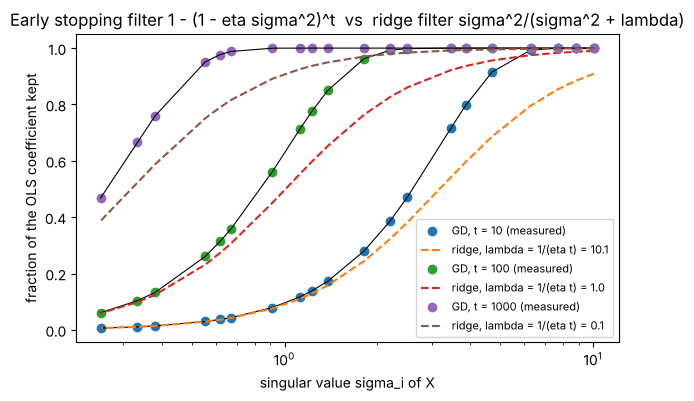

In [10]:
X = rng.normal(size=(100, 20)) @ np.diag(np.logspace(0, -1.5, 20))   # singular values from ~10 down to ~0.3
beta = rng.normal(size=20)
y = X @ beta + 0.5 * rng.normal(size=100)
U, s, Vt = np.linalg.svd(X, full_matrices=False)
w_ols = np.linalg.lstsq(X, y, rcond=None)[0]
eta = 1.0 / s.max() ** 2

w = np.zeros(20); snapshots = {}
for t in range(1, 2001):
    w -= eta * X.T @ (X @ w - y)
    if t in (10, 100, 1000):
        snapshots[t] = w.copy()

for t, w_t in snapshots.items():
    measured = (Vt @ w_t) / (Vt @ w_ols)                        # fraction of OLS reached, per singular direction
    predicted = 1 - (1 - eta * s ** 2) ** t
    plt.plot(s, measured, "o", label=f"GD, t = {t} (measured)")
    plt.plot(s, predicted, "k-", lw=0.8)
    lam = 1 / (eta * t)
    plt.plot(s, s ** 2 / (s ** 2 + lam), "--", label=f"ridge, lambda = 1/(eta t) = {lam:.1f}")
    print(f"t = {t:4d}: max |measured - predicted filter| = {np.abs(measured - predicted).max():.2e}")
plt.xscale("log")
plt.title("Early stopping filter 1 - (1 - eta sigma^2)^t  vs  ridge filter sigma^2/(sigma^2 + lambda)")
plt.xlabel("singular value sigma_i of X"); plt.ylabel("fraction of the OLS coefficient kept"); plt.legend(fontsize=8); plt.show()

The measured fractions sit exactly on the predicted curve $1 - (1 - \eta\sigma_i^2)^t$, and that
curve has the same shape and the same cut-off as ridge with $\lambda \approx 1/(\eta t)$:
directions with large singular values are fitted first, the weakly determined directions —
the ones that carry mostly noise — are fitted last. Stopping early is choosing $\lambda$.

**Try it yourself:** make the noise ten times larger (`5.0 * rng.normal`) and plot the test
error of `snapshots[t]` on fresh data against $t$: it will go down and then up, the
U-curve in the time domain.

## 8. Double descent and the implicit bias of gradient descent

### Double descent with random ReLU features

Features $\phi_j(x) = \max(0, w_j^\top x + b_j)$ with random frozen $w_j, b_j$ — a one-hidden-layer
network whose first layer is never trained. We fit the output weights by *minimum-norm* least
squares (`lstsq`, which is the pseudo-inverse) and vary the number of features $p$ across the
interpolation threshold $p = n$. Target: $f(x) = \sin x_1 + \tfrac12 x_2 x_3$ in $\mathbb{R}^5$,
$n = 40$ training points, noise $\sigma = 0.3$. The variance of the test target is about $0.66$,
so predicting zero would score roughly that.

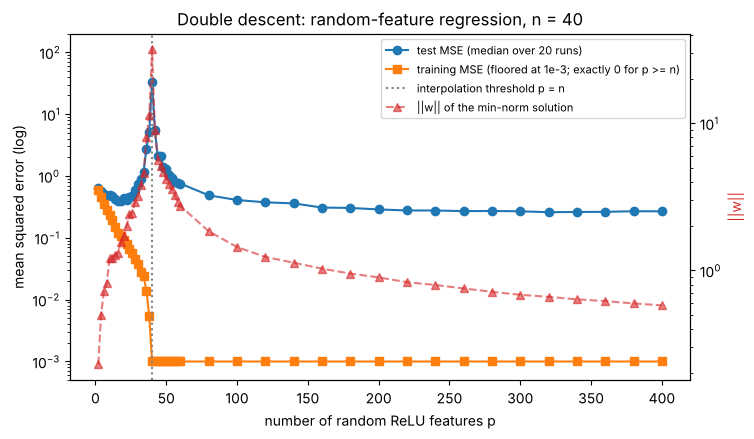

p =  10: median test MSE    0.487   train MSE 2.3e-01   ||w||   1.22
p =  20: median test MSE    0.434   train MSE 9.1e-02   ||w||   1.72
p =  36: median test MSE    2.753   train MSE 1.4e-02   ||w||   8.02
p =  40: median test MSE   32.881   train MSE 1.2e-27   ||w||  31.72
p =  44: median test MSE    2.092   train MSE 6.0e-29   ||w||   5.59
p =  80: median test MSE    0.486   train MSE 9.1e-30   ||w||   1.84
p = 200: median test MSE    0.287   train MSE 7.2e-30   ||w||   0.90
p = 400: median test MSE    0.268   train MSE 7.3e-30   ||w||   0.58

best under-parameterised test MSE 0.391 at p = 16;   at p = 400: 0.268


In [11]:
def target(X):
    return np.sin(X[:, 0]) + 0.5 * X[:, 1] * X[:, 2]

def relu_features(X, W, b):
    return np.maximum(0.0, X @ W + b)

n_train, n_test, d_in, sigma = 40, 400, 5, 0.3
ps = np.unique(np.concatenate([np.arange(2, 60, 2), np.arange(60, 401, 20)]))
reps = 20
test_mse = np.zeros((reps, len(ps))); train_mse = np.zeros_like(test_mse); w_norm = np.zeros_like(test_mse)
for r in range(reps):
    X_tr = rng.normal(size=(n_train, d_in)); y_tr = target(X_tr) + sigma * rng.normal(size=n_train)
    X_te = rng.normal(size=(n_test, d_in)); y_te = target(X_te)
    W = rng.normal(size=(d_in, ps.max())); b = rng.uniform(-1, 1, ps.max())
    for j, p in enumerate(ps):
        Phi, Phi_te = relu_features(X_tr, W[:, :p], b[:p]), relu_features(X_te, W[:, :p], b[:p])
        w = np.linalg.lstsq(Phi, y_tr, rcond=None)[0]           # minimum-norm least squares
        test_mse[r, j] = np.mean((Phi_te @ w - y_te) ** 2)
        train_mse[r, j] = np.mean((Phi @ w - y_tr) ** 2)
        w_norm[r, j] = np.linalg.norm(w)
med_test, med_train, med_norm = (np.median(a, axis=0) for a in (test_mse, train_mse, w_norm))

fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.semilogy(ps, med_test, "o-", label="test MSE (median over 20 runs)")
ax1.semilogy(ps, np.maximum(med_train, 1e-3), "s-", label="training MSE (floored at 1e-3; exactly 0 for p >= n)")
ax1.axvline(n_train, color="gray", ls=":", label="interpolation threshold p = n")
ax1.set_ylim(5e-4, 200)
ax1.set_xlabel("number of random ReLU features p"); ax1.set_ylabel("mean squared error (log)")
ax2 = ax1.twinx(); ax2.semilogy(ps, med_norm, "^--", color="tab:red", alpha=0.6, label="||w|| of the min-norm solution")
ax2.set_ylabel("||w||", color="tab:red")
ax1.set_title(f"Double descent: random-feature regression, n = {n_train}")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper right", fontsize=8); plt.show()

for p in (10, 20, 36, 40, 44, 80, 200, 400):
    j = int(np.where(ps == p)[0][0])
    print(f"p = {p:3d}: median test MSE {med_test[j]:8.3f}   train MSE {med_train[j]:.1e}   ||w|| {med_norm[j]:6.2f}")
under = ps < n_train
print(f"\nbest under-parameterised test MSE {med_test[under].min():.3f} at p = {ps[under][np.argmin(med_test[under])]};"
      f"   at p = 400: {med_test[-1]:.3f}")

The classical U-curve is there for $p < n$: test error is minimal around $p \approx 18$ and
rises as $p \to n$. At $p = n$ the design matrix is square and nearly singular, the minimum-norm
solution must use enormous weights to interpolate, and the test error explodes (training error
is exactly zero from here on). Beyond the threshold the extra features give the interpolator
room to fit the data with *small* weights again — $\|w\|$ falls steadily — and the test error
descends a second time, ending **below** the best under-parameterised model. The red curve is
the mechanism: past the peak, more parameters mean a smaller, smoother interpolator.

**Try it yourself:** set `sigma = 0.0`. Without label noise the peak at $p = n$ shrinks
dramatically — the spike is the noise being interpolated with huge weights.

### Gradient descent from zero finds the minimum-norm interpolator

With $p > n$ there are infinitely many $w$ with $Xw = y$. Gradient descent on
$\tfrac12\|Xw - y\|^2$ from $w_0 = 0$ only ever adds multiples of rows of $X$, so it stays in
the row space and converges to the unique interpolator there: $X^{+}y$.

GD from zero:        max |w_GD - pinv(X) y| = 2.7e-15,  ||w|| = 4.0912
pinv solution:       ||w|| = 4.0912   (w_true has ||w|| = 7.4242 and is NOT recovered)
GD from random w0:   interpolates? True   ||w|| = 6.9573
                     max |w_GD - (pinv(X) y + null-space part of w0)| = 6.3e-15


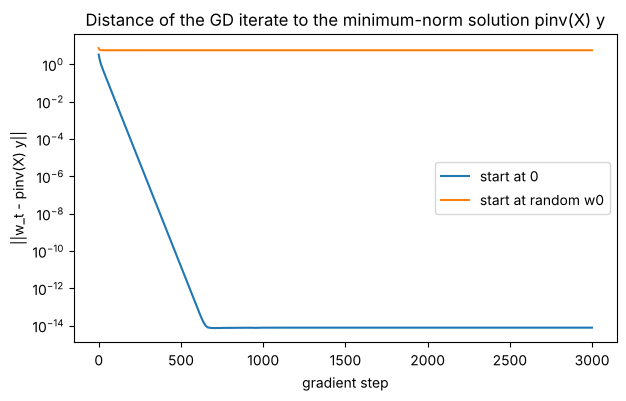

In [12]:
n, p = 20, 50
X = rng.normal(size=(n, p)); w_true = rng.normal(size=p); y = X @ w_true     # noiseless, p > n
w_pinv = np.linalg.pinv(X) @ y
lr = 1.0 / np.linalg.norm(X, 2) ** 2

def gd_least_squares(X, y, w0, lr, steps=3000):
    w = w0.copy(); dist = []
    for _ in range(steps):
        w -= lr * X.T @ (X @ w - y)
        dist.append(np.linalg.norm(w - w_pinv))
    return w, np.array(dist)

w_gd0, dist0 = gd_least_squares(X, y, np.zeros(p), lr)
w0 = rng.normal(size=p)
w_gd1, dist1 = gd_least_squares(X, y, w0, lr)
null_part = w0 - np.linalg.pinv(X) @ (X @ w0)       # component of w0 in the null space of X

print(f"GD from zero:        max |w_GD - pinv(X) y| = {np.abs(w_gd0 - w_pinv).max():.1e},  ||w|| = {np.linalg.norm(w_gd0):.4f}")
print(f"pinv solution:       ||w|| = {np.linalg.norm(w_pinv):.4f}   (w_true has ||w|| = {np.linalg.norm(w_true):.4f} and is NOT recovered)")
print(f"GD from random w0:   interpolates? {np.allclose(X @ w_gd1, y)}   ||w|| = {np.linalg.norm(w_gd1):.4f}")
print(f"                     max |w_GD - (pinv(X) y + null-space part of w0)| = {np.abs(w_gd1 - (w_pinv + null_part)).max():.1e}")
plt.semilogy(dist0, label="start at 0")
plt.semilogy(dist1, label="start at random w0")
plt.title("Distance of the GD iterate to the minimum-norm solution pinv(X) y")
plt.xlabel("gradient step"); plt.ylabel("||w_t - pinv(X) y||"); plt.legend(); plt.show()

From zero, GD lands on `pinv(X) @ y` to machine precision: the optimiser *is* the regulariser.
From a random start it still interpolates, but it keeps the null-space component of its starting
point forever (the gradient can never see it), so the limit is the minimum-norm solution plus
that frozen component — larger in norm and no better on new data. Initialisation scale is a
regularisation choice too.

### Learning curves and a fitted power law

Test error against $n$ for two polynomial classes on $y = \sin(2\pi x) + \varepsilon$. For a
well-specified class with $p$ parameters, theory says the generalisation *gap* (test minus train
MSE) is about $2\sigma^2 p/n$, i.e. a power law with exponent $-1$. A misspecified class sees
its own approximation error as extra noise, so the fair comparison uses the residual variance
$\sigma_{\text{eff}}^2 = \sigma^2 + \text{approximation error}$ in place of $\sigma^2$. We fit
$c\,n^{-\gamma}$ to the measured gap and overlay $2\sigma_{\text{eff}}^2 p/n$.

degree 1: approximation error 0.1964, sigma_eff^2 = 0.2864;  test MSE [0.321 0.305 0.296 0.289 0.289 0.286];  fitted gap ~ 1.82 n^(-1.07) vs theory 1.15 / n


degree 5: approximation error 0.0000, sigma_eff^2 = 0.0900;  test MSE [0.369 0.118 0.098 0.094 0.092 0.091];  fitted gap ~ 7.30 n^(-1.29) vs theory 1.08 / n


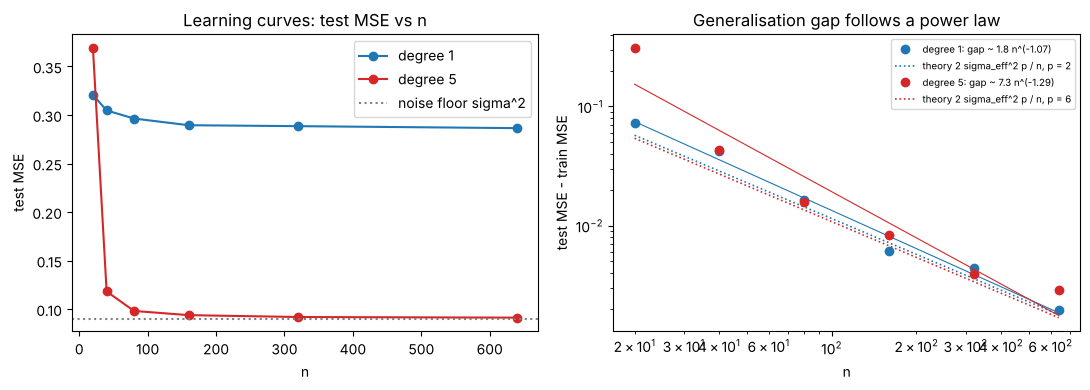

In [13]:
f_true = lambda x: np.sin(2 * np.pi * x)
sigma = 0.3
ns = np.array([20, 40, 80, 160, 320, 640])
grid = np.linspace(0, 1, 2001)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for deg, c in ((1, "tab:blue"), (5, "tab:red")):
    approx_err = np.mean((np.polyval(np.polyfit(grid, f_true(grid), deg), grid) - f_true(grid)) ** 2)
    sigma_eff2 = sigma ** 2 + approx_err                      # what a misspecified model sees as noise
    test, gap = [], []
    for n in ns:
        te, g = [], []
        for _ in range(100):
            x = rng.uniform(0, 1, n); y = f_true(x) + sigma * rng.normal(size=n)
            coef = np.polyfit(x, y, deg)
            xt = rng.uniform(0, 1, 2000); yt = f_true(xt) + sigma * rng.normal(size=2000)
            tr_e = np.mean((np.polyval(coef, x) - y) ** 2); te_e = np.mean((np.polyval(coef, xt) - yt) ** 2)
            te.append(te_e); g.append(te_e - tr_e)
        test.append(np.mean(te)); gap.append(np.mean(g))
    test, gap = np.array(test), np.array(gap)
    slope, icpt = np.polyfit(np.log(ns), np.log(gap), 1)
    axes[0].plot(ns, test, "o-", color=c, label=f"degree {deg}")
    axes[1].loglog(ns, gap, "o", color=c, label=f"degree {deg}: gap ~ {np.exp(icpt):.1f} n^({slope:.2f})")
    axes[1].loglog(ns, np.exp(icpt) * ns ** slope, "-", color=c, lw=0.8)
    axes[1].loglog(ns, 2 * sigma_eff2 * (deg + 1) / ns, ":", color=c, lw=1.2, label=f"theory 2 sigma_eff^2 p / n, p = {deg+1}")
    print(f"degree {deg}: approximation error {approx_err:.4f}, sigma_eff^2 = {sigma_eff2:.4f};  test MSE {np.round(test, 3)};"
          f"  fitted gap ~ {np.exp(icpt):.2f} n^({slope:.2f}) vs theory {2 * sigma_eff2 * (deg + 1):.2f} / n")
axes[0].axhline(sigma ** 2, color="gray", ls=":", label="noise floor sigma^2")
axes[0].set_title("Learning curves: test MSE vs n"); axes[0].set_xlabel("n"); axes[0].set_ylabel("test MSE"); axes[0].legend()
axes[1].set_title("Generalisation gap follows a power law"); axes[1].set_xlabel("n"); axes[1].set_ylabel("test MSE - train MSE"); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

The straight line (degree 1) plateaus far above the noise floor: its approximation error
($\approx 0.20$) never goes away. Degree 5 is misspecified too, but barely, and its curve
approaches $\sigma^2$. Both gaps follow power laws with exponents near $-1$, and for $n \ge 80$
they sit on the $2\sigma_{\text{eff}}^2 p/n$ line once the approximation error is counted as noise.
The fitted constants come out larger than the theory's because the smallest sample sizes pull
the fit up: with a uniform design and few points the variance term exceeds its $p/n$
approximation, and $p = 6$ parameters on $n = 20$ points is already near the $p \approx n$
instability of Section 8. The large-language-model scaling laws
of the guide — $L = E + A/N^\alpha + B/D^\beta$ — are this picture with far shallower
exponents ($\beta \approx 0.28$) on far harder targets.

## 9. Covariate shift: the same function, a different population

Train on $x \sim \mathcal N(0.3, 0.5^2)$, deploy on $x \sim \mathcal N(1.0, 0.25^2)$; the regression
function $f(x) = x^3 - x$ never changes, so this is pure **covariate shift**. A straight line is
misspecified, and the best line for one input distribution is a bad line for the other: around
$x = 0.3$ the cubic is almost flat, around $x = 1$ it climbs steeply.
**Importance weighting** — multiplying each training loss by $w(x) = p_{\text{test}}(x)/p_{\text{train}}(x)$ —
turns the training ERM into an unbiased estimate of the test risk.

in-distribution test                     mean MSE 0.2155  (sd over runs 0.0558)
shifted test, unweighted fit             mean MSE 0.4683  (sd over runs 0.1380)
shifted test, importance-weighted fit    mean MSE 0.0894  (sd over runs 0.0284)
effective sample size of the last weighted fit: 20.0 of 100


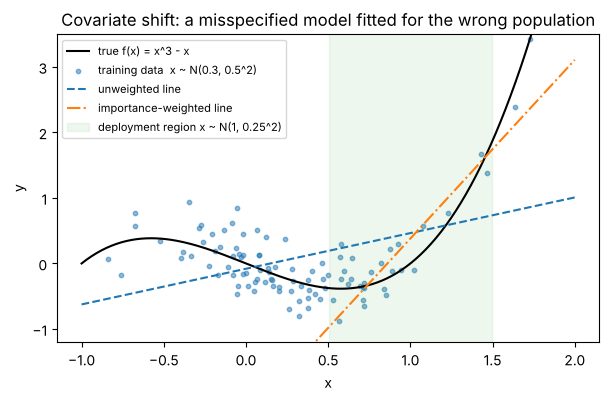

In [14]:
from scipy.stats import norm

f_shift = lambda x: x ** 3 - x
mu_tr, sd_tr, mu_te, sd_te, n = 0.3, 0.5, 1.0, 0.25, 100
mse = {"in-distribution test": [], "shifted test, unweighted fit": [], "shifted test, importance-weighted fit": []}
for _ in range(200):
    x_tr = rng.normal(mu_tr, sd_tr, n); y_tr = f_shift(x_tr) + 0.3 * rng.normal(size=n)
    x_same, x_shift = rng.normal(mu_tr, sd_tr, 4000), rng.normal(mu_te, sd_te, 4000)
    c = np.polyfit(x_tr, y_tr, 1)
    w_imp = norm.pdf(x_tr, mu_te, sd_te) / norm.pdf(x_tr, mu_tr, sd_tr)        # density ratio
    c_w = np.polyfit(x_tr, y_tr, 1, w=np.sqrt(w_imp))                            # weighted least squares
    mse["in-distribution test"].append(np.mean((np.polyval(c, x_same) - f_shift(x_same)) ** 2))
    mse["shifted test, unweighted fit"].append(np.mean((np.polyval(c, x_shift) - f_shift(x_shift)) ** 2))
    mse["shifted test, importance-weighted fit"].append(np.mean((np.polyval(c_w, x_shift) - f_shift(x_shift)) ** 2))
for k, v in mse.items():
    print(f"{k:40s} mean MSE {np.mean(v):.4f}  (sd over runs {np.std(v):.4f})")
print(f"effective sample size of the last weighted fit: {w_imp.sum()**2 / (w_imp**2).sum():.1f} of {n}")

xs = np.linspace(-1, 2, 300)
plt.plot(xs, f_shift(xs), "k", label="true f(x) = x^3 - x")
plt.scatter(x_tr, y_tr, s=10, alpha=0.5, label="training data  x ~ N(0.3, 0.5^2)")
plt.plot(xs, np.polyval(c, xs), "--", label="unweighted line")
plt.plot(xs, np.polyval(c_w, xs), "-.", label="importance-weighted line")
plt.fill_between(xs, -2, 4, where=(np.abs(xs - mu_te) < 2 * sd_te), color="tab:green", alpha=0.08, label="deployment region x ~ N(1, 0.25^2)")
plt.ylim(-1.2, 3.5); plt.title("Covariate shift: a misspecified model fitted for the wrong population")
plt.xlabel("x"); plt.ylabel("y"); plt.legend(fontsize=8); plt.show()

The unweighted line is tuned to where the training data are dense ($x \approx 0.3$, where the
cubic is nearly flat) and is almost horizontal; in the deployment region the true function has
slope about $2$, and the shifted-test MSE is more than double the in-distribution one. Re-weighting
the training points by the density ratio fits the line for the deployment population and cuts
the shifted error by a factor of about five, at the cost of a smaller effective sample size
(about 20 of 100 — a few points in the right tail carry most of the weight). The i.i.d. test
set from the training distribution — the first row — would never have revealed the problem;
only data from the deployment distribution can. With a well-specified model (try degree 3)
the unweighted fit is already fine under the shift: covariate shift hurts *because* the class
is wrong somewhere, and importance weighting then trades bias for variance.

## 10. A leakage trap: feature selection outside the folds

100 samples, 5,000 features of pure noise, random labels — nothing is learnable. Select the 50
features most correlated with the label *using all the data*, then cross-validate a classifier
on them: the score is spectacular and completely wrong, because every test fold's labels were
used to choose the features. Putting the selection inside a `Pipeline` repeats it on each
training fold only.

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, KFold
from sklearn.pipeline import make_pipeline
from sklearn.feature_selection import SelectKBest, f_classif

n, p = 100, 5000
X_noise = rng.normal(size=(n, p)); y_rand = rng.integers(0, 2, n)
cv = KFold(10, shuffle=True, random_state=0)

corr = np.abs((X_noise - X_noise.mean(0)).T @ (y_rand - y_rand.mean()))
top50 = np.argsort(-corr)[:50]                               # selection sees ALL labels -> leakage
leaky = cross_val_score(LogisticRegression(max_iter=1000), X_noise[:, top50], y_rand, cv=cv)

proper = cross_val_score(make_pipeline(SelectKBest(f_classif, k=50), LogisticRegression(max_iter=1000)),
                         X_noise, y_rand, cv=cv)              # selection re-fitted inside every training fold
print(f"leaky protocol:  10-fold CV accuracy {leaky.mean():.3f} +- {leaky.std():.3f}   (data are pure noise!)")
print(f"proper pipeline: 10-fold CV accuracy {proper.mean():.3f} +- {proper.std():.3f}   (chance = 0.5)")

leaky protocol:  10-fold CV accuracy 0.920 +- 0.075   (data are pure noise!)
proper pipeline: 10-fold CV accuracy 0.570 +- 0.110   (chance = 0.5)


The leaky protocol reports over 90 % accuracy on data with no signal; the honest one reports
chance. Every bound in this module assumes the test data were untouched by the training
process — including by preprocessing, feature selection and hyper-parameter choices. The
`Pipeline` is how you make that assumption true in code.

## Summary

- Training error is biased by selection; a test set restores the fixed-hypothesis setting in
  which $\hat R_S(h)$ is an unbiased, concentrating estimate of $R(h)$.
- Excess risk = approximation + estimation (+ optimisation); the U-curve is their sum.
- Hoeffding: $P(|\hat p - p| \ge t) \le 2e^{-2nt^2}$ — valid, loose, and exponential, which is
  what makes the union bound cheap. About 4,600 examples pin an accuracy to ±0.02 at 95 %.
- The best of $m$ models on a validation set is optimistic by roughly
  $\sqrt{2\ln m}\cdot\text{SE}$; the union bound gives the distribution-free envelope.
- Lines in the plane shatter 3 points but not 4; Sauer's lemma makes the growth function
  polynomial; VC bounds fall like $\sqrt{d\ln n/n}$ with pessimistic constants.
- Realisable learning curves fall like $1/n$; agnostic ones like $1/\sqrt n$.
- Among zero-training-error separators, larger margin means lower test error, independently
  of dimension; early stopping reproduces ridge's filter with $\lambda \approx 1/(\eta t)$.
- Random-feature regression shows double descent with a spike at $p = n$ and a second
  descent driven by shrinking $\|w\|$; GD from zero converges to the minimum-norm interpolator.
- Covariate shift breaks a misspecified model even though $P(y \mid x)$ is unchanged;
  importance weighting repairs it at the price of effective sample size.
- Feature selection outside the folds turns pure noise into 90 %+ accuracy — use a `Pipeline`.

## Next: open `exercises.ipynb`

Eleven exercises with instant self-checks, from Hoeffding sample sizes to a mini-project that
fits a power law to the generalisation gap.